# TerraSpectra — Week 2: a small model and a practice heatmap

**Read this like a story, then run it one cell at a time.** Last week we made 16 summary pages from 125 spectral pages. This week we teach a small model to recognize Health, Other and Rust image patches. We also draw a coloured practice grid on a map.

These are two different outputs: the classifier learns from actual images; the map uses explicitly invented JSON values. The dataset does not tell us where the patches belong on the demonstration farm.

Choose the project `.venv` kernel in VS Code. The saved model and reports are included, so opening this notebook does not automatically start training.

## 1. Open our toolbox

A Python import is like taking a tool out of a drawer. We find the project folder and use the same small modules as the training command. This prevents the notebook and application from quietly using different model definitions.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import csv
import json
import numpy as np
import matplotlib.pyplot as plt
import torch

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
assert (ROOT / "src/terraspectra").exists(), "Open the notebook in the tspectra repository."
sys.path.insert(0, str(ROOT / "src"))
from terraspectra.data import CLASS_NAMES, PatchDataset, make_input
from terraspectra.model import HybridCNN, load_model
from terraspectra.predict import predict, preprocess_tiff

torch.set_num_threads(2)
print("PyTorch:", torch.__version__)
print("Class order:", CLASS_NAMES)


PyTorch: 2.8.0
Class order: ['Health', 'Other', 'Rust']


## 2. Check the available answers

There are 480 training and 120 development-validation examples. The 300 other files have no known answers. `Other` is its own class; we must not rename it “chemical stress.” Each answer belongs to a whole image patch, not every pixel.

The validation set helps choose the saved model, so its score is a development result. It is not a separate final exam. Patches may also share an original scene because scene/date IDs are not available.

In [2]:
training = PatchDataset("train", ROOT)
validation = PatchDataset("validation", ROOT)
print("Training:", len(training), "Validation:", len(validation))
print("Training counts:", dict(zip(CLASS_NAMES, torch.bincount(training.labels).tolist())))
print("Validation counts:", dict(zip(CLASS_NAMES, torch.bincount(validation.labels).tolist())))
print("Cached input memory (MiB):", (training.inputs.numel()+validation.inputs.numel())*4/1024**2)


Training: 480 Validation: 120
Training counts: {'Health': 160, 'Other': 160, 'Rust': 160}
Validation counts: {'Health': 40, 'Other': 40, 'Rust': 40}
Cached input memory (MiB): 9.375


## 3. Make the model's input easy to understand

One original PCA picture is `(64,64,16)`. Average each 4×4 square to make a smaller whole picture. Then move the page axis in front. The resulting shape is `(1,16,16,16)`: one stack, 16 summary pages, 16 pixels high, 16 pixels wide.

This is faster but can lose fine details. The PCA pages mix wavelengths; their order is by variation, not physical wavelength spacing.

Original PCA image: (64, 64, 16)
One model input: (1, 16, 16, 16)
Batch of 16: (16, 1, 16, 16, 16)


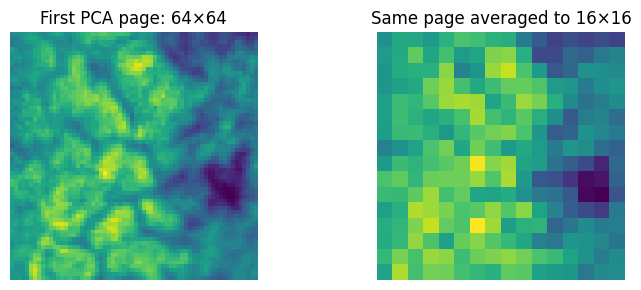

In [3]:
row = training.rows[0]
original = np.load(ROOT / "data/processed" / row["processed_path"], allow_pickle=False)
small = make_input(original)
print("Original PCA image:", original.shape)
print("One model input:", tuple(small.shape))
print("Batch of 16:", tuple(training.inputs[:16].shape))
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].imshow(original[:, :, 0], cmap="viridis")
axes[0].set_title("First PCA page: 64×64")
axes[1].imshow(small[0, 0], cmap="viridis")
axes[1].set_title("Same page averaged to 16×16")
for axis in axes: axis.axis("off")
plt.tight_layout()
plt.show()


## 4. Follow the image through the hybrid CNN

A **3D filter** is a small moving window that looks across the page stack and nearby image squares. Two 3D layers learn pattern stacks. Then we fold depth into feature channels and use a **2D filter** across the image. That combination is why it is called a hybrid.

We average each final pattern map to one number and produce three raw scores called logits. There is no transformer yet: attention is Week 3. This model is inspired by the HybridSN idea, but it is a smaller original implementation, not an exact reproduction of its paper.

In [4]:
model, checkpoint = load_model(ROOT / "models/week2/hybrid_cnn.pt")
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))
with torch.inference_mode():
    x = training.inputs[:2]
    stacks = model.spectral_spatial(x)
    folded = stacks.flatten(1, 2)
    logits = model.spatial(folded)
print("Input:", tuple(x.shape))
print("After 3D layers:", tuple(stacks.shape))
print("After folding:", tuple(folded.shape))
print("Output logits:", tuple(logits.shape))


HybridCNN(
  (spectral_spatial): Sequential(
    (0): Conv3d(1, 8, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
    (1): BatchNorm3d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv3d(8, 12, kernel_size=(3, 3, 3), stride=(2, 2, 2), padding=(1, 1, 1))
    (4): BatchNorm3d(12, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
  )
  (spatial): Sequential(
    (0): Conv2d(96, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): AdaptiveAvgPool2d(output_size=1)
    (3): Flatten(start_dim=1, end_dim=-1)
    (4): Dropout(p=0.2, inplace=False)
    (5): Linear(in_features=24, out_features=3, bias=True)
  )
)
Trainable parameters: 23703
Input: (2, 1, 16, 16, 16)
After 3D layers: (2, 12, 8, 8, 8)
After folding: (2, 96, 8, 8)
Output logits: (2, 3)


## 5. How learning works

Imagine practice questions with known answers. The model guesses, cross-entropy measures the mistake, backpropagation finds useful weight changes, and Adam makes a small update. An epoch is one pass through the 480 practice pictures.

The script uses batches of 16, two CPU threads, a maximum of 20 epochs and early stopping after five validation-loss checks without improvement. It saves the lowest-loss checkpoint. Dropout hides some features only during training; `eval()` disables that randomness for prediction.

The baseline uses the average and spread of each PCA page: 32 numbers. Logistic regression learns from them. Its scaler fits training examples only.

**Optional:** set `RUN_TRAINING=True` below to repeat the run. This overwrites Week 2 artifacts. Leave it False to use the completed run. The measured runtime is specific to this machine.

In [5]:
RUN_TRAINING = False
if RUN_TRAINING:
    import os
    import subprocess
    subprocess.run([sys.executable, "-m", "terraspectra.train", "--epochs", "20",
                    "--batch-size", "16", "--patience", "5", "--device", "cpu"],
                   cwd=ROOT, env={**os.environ, "PYTHONPATH": str(ROOT / "src")}, check=True)
else:
    print("Using the supplied trained model and recorded metrics; no new training started.")


Using the supplied trained model and recorded metrics; no new training started.


## 6. Read the real results, including the weaknesses

Accuracy counts all correct answers. Macro F1 gives each class equal importance while combining precision and recall. The two metrics can disagree.

The CNN gets slightly higher accuracy, but the baseline has higher macro F1. In the recorded CNN confusion matrix only 12 of 40 Health patches are correctly recognized. Twenty are called Rust. We must report this error pattern rather than call the model ready for real farm decisions.

In [6]:
report = json.loads((ROOT / "reports/week2/metrics.json").read_text())
for name, scores in [("CNN", report["cnn"]), ("Logistic baseline", report["baseline"])]:
    print(f"{name}: accuracy {scores['accuracy']:.2%}, macro F1 {scores['macro_f1']:.3f}")
print("Epochs run / saved epoch:", report["epochs_run"], "/", report["best_epoch"])
print("Measured training + evaluation seconds:", round(report["elapsed_seconds"], 2))
print("Measured peak process memory MiB:", round(report["peak_process_memory_mib"], 2))
print("Health recall:", report["cnn"]["per_class"]["Health"]["recall"])


CNN: accuracy 65.83%, macro F1 0.635
Logistic baseline: accuracy 64.17%, macro F1 0.645
Epochs run / saved epoch: 16 / 11
Measured training + evaluation seconds: 55.15
Measured peak process memory MiB: 313.05
Health recall: 0.3


## 7. See the learning curve and confusion matrix

A lower loss means the guesses better match the answers. The dashed line marks the saved epoch. Rows in the confusion matrix are the real class; columns are the model's guess. Correct guesses lie on the diagonal.

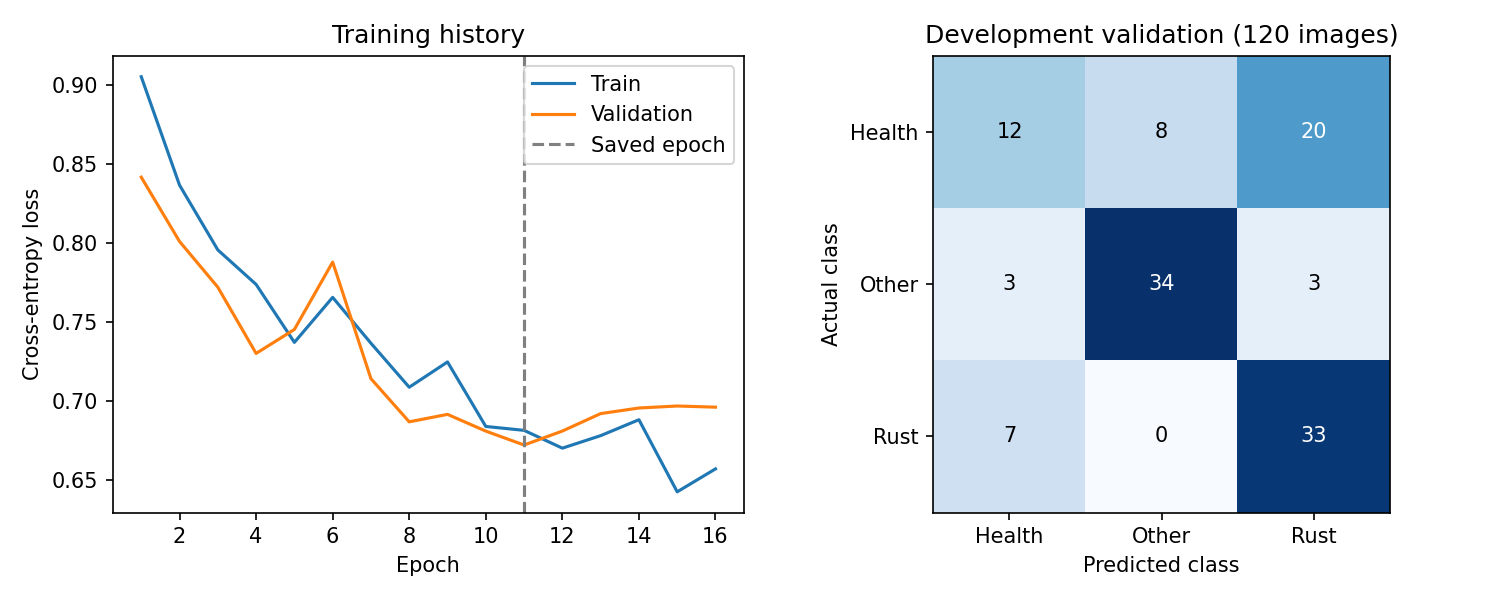

In [7]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "reports/week2/training_results.png")))


## 8. Try the saved model on a real TIFF

Prediction uses the original training scaler and PCA parameters exported as numeric arrays. It never fits a new PCA on the chosen picture. We load tensor weights with `weights_only=True`, switch to evaluation mode, and apply softmax to convert scores into three numbers that sum to one.

Those numbers are uncalibrated class scores. A score of 0.8 is not proven to mean “80% chance of infection.” The example below is a development-validation patch, not a fresh independent test.

In [8]:
example = validation.rows[0]
image_path = ROOT / "data/raw" / example["path"]
result = predict(image_path)
print("Known development label:", example["label"])
print(json.dumps(result, indent=2))
# Confirm exported raw-TIFF preprocessing matches the Week 1 PCA result.
prepared = preprocess_tiff(image_path)
saved = np.load(ROOT / "data/processed" / example["processed_path"], allow_pickle=False)
np.testing.assert_allclose(prepared, saved, rtol=2e-4, atol=2e-4)
print("Exported preprocessing matches Week 1.")


Known development label: Health
{
  "file": "hyper (10).tif",
  "predicted_class": "Health",
  "scores": {
    "Health": 0.7643625736236572,
    "Other": 0.08361484110355377,
    "Rust": 0.152022585272789
  },
  "note": "Uncalibrated patch-class scores; no pixel mask or farm coordinates."
}
Exported preprocessing matches Week 1.


## 9. Inspect real mistakes instead of inventing an explanation

We save predictions for every validation image, so the result can be audited. A wrong answer can have many causes: similar spectral patterns, lost fine detail, mixed patches, limited training examples or the simple model. This table shows mistakes; it does not prove which cause applies.

In [9]:
with (ROOT / "reports/week2/validation_predictions.csv").open() as handle:
    predictions = list(csv.DictReader(handle))
errors = [row for row in predictions if row["true_label"] != row["predicted_label"]]
print("Wrong validation answers:", len(errors), "out of", len(predictions))
for row in errors[:5]:
    print(row["path"], "| actual:", row["true_label"], "| predicted:", row["predicted_label"])


Wrong validation answers: 41 out of 120
train/Health/hyper (118).tif | actual: Health | predicted: Rust
train/Health/hyper (132).tif | actual: Health | predicted: Other
train/Health/hyper (142).tif | actual: Health | predicted: Rust
train/Health/hyper (144).tif | actual: Health | predicted: Rust
train/Health/hyper (148).tif | actual: Health | predicted: Other


## 10. Start a separate map exercise

The screenshot asks for a heatmap based on mock backend JSON. Think of squared paper placed over a farm outline. We create 80 squares and invent two groups of high scores. The file explicitly says `is_mock: true`.

The classifier's predictions are not used here, because their correct geographic positions are unknown. We do not attach predictions to random farm coordinates. A future API could return the same contract when real georeferenced inputs become available.

In [10]:
heatmap = json.loads((ROOT / "frontend/public/mock-heatmap.json").read_text())
assert heatmap["is_mock"] is True
print(heatmap["source"])
print(heatmap["score_meaning"])
print("Rows × columns:", heatmap["rows"], "×", heatmap["columns"])
print("Example cell:", json.dumps(heatmap["cells"][0], indent=2))


Synthetic demonstration; not model predictions or measured disease.
Invented display score from 0 to 1, not an infection probability.
Rows × columns: 8 × 10
Example cell: {
  "id": "cell-0-0",
  "row": 0,
  "column": 0,
  "bounds": [
    77.591,
    13.152,
    77.59179999999999,
    13.15275
  ],
  "score": 0.144
}


## 11. Colour each cell and try a filter

Green means a simulated score below 0.33, amber means 0.33 up to but excluding 0.66, and red means 0.66 or more. These bins stay fixed when the map moves.

The minimum-score slider only hides squares. Opacity only changes transparency. Neither changes the numbers or retrains anything. The white gaps in the filtered picture below are hidden cells, not missing satellite observations.

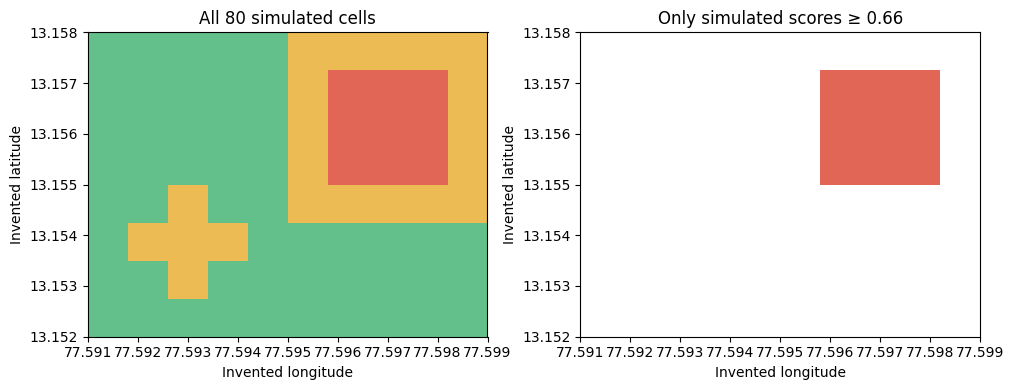

Visible at threshold 0.66: 9


In [11]:
from matplotlib.colors import ListedColormap, BoundaryNorm
values = np.zeros((heatmap["rows"], heatmap["columns"]))
for cell in heatmap["cells"]:
    values[cell["row"], cell["column"]] = cell["score"]
colours = ListedColormap(["#64c08a", "#edbb53", "#e16655"])
norm = BoundaryNorm([0, 0.33, 0.66, 1.00001], colours.N)
west, south, east, north = heatmap["bounds"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for axis, array, title in [(axes[0], values, "All 80 simulated cells"),
                          (axes[1], np.ma.masked_less(values, 0.66), "Only simulated scores ≥ 0.66")]:
    axis.imshow(array, origin="lower", extent=[west, east, south, north], cmap=colours, norm=norm, interpolation="nearest", aspect="auto")
    axis.set(title=title, xlabel="Invented longitude", ylabel="Invented latitude")
    axis.ticklabel_format(useOffset=False)
plt.tight_layout()
plt.savefig(ROOT / "reports/week2/mock_heatmap_preview.png", dpi=150, bbox_inches="tight")
plt.show()
print("Visible at threshold 0.66:", int((values >= 0.66).sum()))


## 12. Connect the JSON to React and Deck.gl

`FarmMap.tsx` fetches the JSON like a future API response. `heatmap.ts` checks the numbers and creates one GeoJSON polygon per square. A polygon lists its corners as **[longitude, latitude]**, repeating the first corner at the end.

Deck.gl's `GeoJsonLayer` colours and picks the polygons. `MapboxOverlay` keeps them aligned with the map camera. We use polygon cells because Deck.gl's separately named `HeatmapLayer` smooths point densities into blobs.

Without a Mapbox token, `HeatmapPreview.tsx` draws the same grid as an interactive SVG. Row zero is south; the SVG flips vertical screen coordinates to keep north at the top. This preview is labelled as a diagram, not satellite imagery.

**Try in the browser:** toggle the heatmap and boundary, change opacity, move minimum score to 1 (no cells), reset it to 0, select a cell, and use Tab + Enter in the diagram. With a token, also pan/zoom/tilt the geographic map. No token is included in GitHub.

## 13. Explain the work at your internship review

“I trained a compact 3D–2D CNN on the prepared patches and compared it with a logistic baseline. I saved the best development checkpoint, preprocessing parameters, predictions and error analysis. The results show that Health and Rust still need better separation. I built a clickable heatmap from explicitly mock JSON and kept it separate from actual predictions because geographic labels are unavailable.”

**Week 3:** test whether attention improves results using the same clear evaluation protocol. More complicated code is useful only if evidence supports it.

Further reading: [Week 2 guide](../docs/WEEK_2_GUIDE.md), [research and sources](../docs/WEEK_2_RESEARCH.md), [validation record](../docs/WEEK_2_VALIDATION.md), [HybridSN paper](https://arxiv.org/abs/1902.06701), [Conv3d documentation](https://docs.pytorch.org/docs/2.8/generated/torch.nn.Conv3d.html), [Deck.gl GeoJsonLayer](https://deck.gl/docs/api-reference/layers/geojson-layer).